In [2]:
# As always, we import the relevant packages
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import librosa
import sklearn
import tensorflow as tf
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
from tensorflow.keras import regularizers
import pandas as pd
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
plt.style.use("seaborn-v0_8")

Load the ESC-50 dataset and select the first 10 classes.

In [5]:
fn_csv = 'ESC-50-master/meta/esc50.csv'

df = pd.read_csv(fn_csv)
print(df.head())
unique_classes = df['category'].unique()
print(f"Unique classes: {unique_classes}")

files = []
labels = []

for row in df.values:
    if row[2] < 10:
        files.append(row[0])
        labels.append(row[2])

print(f"Number of files: {len(files)}")
print(f"Number of labels: {len(labels)}")

            filename  fold  target        category  esc10  src_file take
0   1-100032-A-0.wav     1       0             dog   True    100032    A
1  1-100038-A-14.wav     1      14  chirping_birds  False    100038    A
2  1-100210-A-36.wav     1      36  vacuum_cleaner  False    100210    A
3  1-100210-B-36.wav     1      36  vacuum_cleaner  False    100210    B
4  1-101296-A-19.wav     1      19    thunderstorm  False    101296    A
Unique classes: ['dog' 'chirping_birds' 'vacuum_cleaner' 'thunderstorm' 'door_wood_knock'
 'can_opening' 'crow' 'clapping' 'fireworks' 'chainsaw' 'airplane'
 'mouse_click' 'pouring_water' 'train' 'sheep' 'water_drops'
 'church_bells' 'clock_alarm' 'keyboard_typing' 'wind' 'footsteps' 'frog'
 'cow' 'brushing_teeth' 'car_horn' 'crackling_fire' 'helicopter'
 'drinking_sipping' 'rain' 'insects' 'laughing' 'hen' 'engine' 'breathing'
 'crying_baby' 'hand_saw' 'coughing' 'glass_breaking' 'snoring'
 'toilet_flush' 'pig' 'washing_machine' 'clock_tick' 'sneezing' 'r

Load the audios and compute the melspectrogram with default parameters.

In [9]:
audio_folder = 'ESC-50-master/audio/'

signals = []
melspecs = []
for i in range(len(files)):
    signals.append(librosa.load(audio_folder + files[i]))
    melspecs.append(librosa.feature.melspectrogram(y=signals[i][0]))

Xdata = np.asarray(melspecs)
Ydata = np.asarray(labels)
print(f"Xdata shape: {Xdata.shape}")
print(f"Ydata shape: {Ydata.shape}")
                    

Xdata shape: (400, 128, 216)
Ydata shape: (400,)


Generate Train Val and Test sets

In [17]:
train_size = 0.7
val_size = 0.2
test_size = 0.1

seed = 1234
X_train, X_temp, y_train, y_temp = train_test_split(Xdata, Ydata, train_size=train_size, random_state=seed, shuffle=True , stratify=Ydata)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=np.round(test_size/(test_size + val_size),2), random_state=seed, shuffle=True , stratify=y_temp)


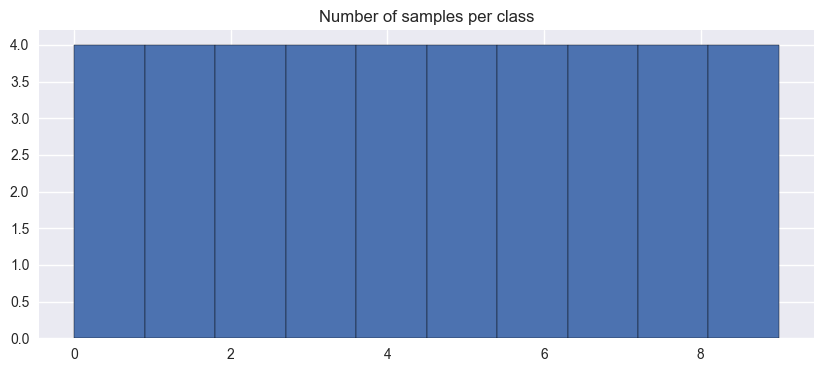

In [18]:
plt.figure(figsize=(10, 4))
plt.title("Number of samples per class")
plt.hist(y_test, bins=10,edgecolor='black')
plt.show()

Prepare data for CNN2D

In [20]:
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_val_cnn = np.expand_dims(X_val, axis=-1)
X_test_cnn = np.expand_dims(X_test, axis=-1)
print(f"X_train_cnn shape: {X_train_cnn.shape}")
print(f"X_val_cnn shape: {X_val_cnn.shape}")
print(f"X_test_cnn shape: {X_test_cnn.shape}")

X_train_cnn shape: (280, 128, 216, 1)
X_val_cnn shape: (80, 128, 216, 1)
X_test_cnn shape: (40, 128, 216, 1)


Develop the model:

### Input
- Shape: `(H, W, C)` → from `X_train_cnn.shape[1:]`

### Convolutional Blocks

#### Block 1
- `Conv2D(16 filters, 3x3, ReLU, padding='same', L2=0.001)`  
- `MaxPooling2D(2x2, padding='same')`  
- `BatchNormalization`  
- `Dropout(0.25)`

#### Block 2
- `Conv2D(16 filters, 3x3, ReLU, padding='same', L2=0.001)`  
- `MaxPooling2D(2x2, padding='same')`  
- `BatchNormalization`  
- `Dropout(0.25)`

#### Block 3
- `Conv2D(32 filters, 3x3, ReLU, padding='same', L2=0.001)`  
- `MaxPooling2D(2x2, padding='same')`  
- `BatchNormalization`  
- `Dropout(0.25)`

### Fully Connected Layers
- `Flatten`  
- `Dense(32, ReLU, L2=0.001)`  
- `Dropout(0.5)`  
- `Dense(10, Softmax)` — Output layer for classification

In [22]:
input_shape = (X_train_cnn.shape[1], X_train_cnn.shape[2], X_train_cnn.shape[3])
print(f"Input shape: {input_shape}")

# Define the CNN model
modelC2D = tf.keras.models.Sequential()

# Block 1
modelC2D.add(tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(0.001), input_shape=input_shape))
modelC2D.add(tf.keras.layers.MaxPooling2D((2, 2), padding='same'))
modelC2D.add(tf.keras.layers.BatchNormalization())
modelC2D.add(tf.keras.layers.Dropout(0.25))

# Block 2
modelC2D.add(tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(0.001), input_shape=input_shape))
modelC2D.add(tf.keras.layers.MaxPooling2D((2, 2), padding='same'))
modelC2D.add(tf.keras.layers.BatchNormalization())
modelC2D.add(tf.keras.layers.Dropout(0.25))

# Block 2
modelC2D.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(0.001), input_shape=input_shape))
modelC2D.add(tf.keras.layers.MaxPooling2D((2, 2), padding='same'))
modelC2D.add(tf.keras.layers.BatchNormalization())
modelC2D.add(tf.keras.layers.Dropout(0.25))

# Fully connected layers
modelC2D.add(tf.keras.layers.Flatten())
modelC2D.add(tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
modelC2D.add(tf.keras.layers.Dropout(0.5))
modelC2D.add(tf.keras.layers.Dense(10, activation='softmax'))

modelC2D.summary()

Input shape: (128, 216, 1)


/Users/carabias/miniconda3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 128, 216, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 108, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 108, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 108, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 108, 16)    │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 54, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 54, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 27, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 27, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 27, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       442,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 450,106 (1.72 MB)

 Trainable params: 449,978 (1.72 MB)

 Non-trainable params: 128 (512.00 B)

Define callbacks, optimizer and compile it.

In [ ]:
# CSVLogger
csv_logger = CSVLogger('training_C2D.log', append=False)

# EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=100)

# ModelCheckpoint
model_name = 'C2D_model.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Compile the model
opt = tf.keras.optimizers.Adam(learning_rate=0.001)
modelC2D.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])


Fit the model:

In [24]:
batch_size = 32
history = modelC2D.fit(X_train_cnn, y_train, batch_size=batch_size, epochs=1000, validation_data=(X_val_cnn, y_val), callbacks=callbacks)

Epoch 1/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.1010 - loss: 3.3179
Epoch 1: val_accuracy improved from -inf to 0.18750, saving model to C2D_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 278ms/step - accuracy: 0.1031 - loss: 3.2978 - val_accuracy: 0.1875 - val_loss: 4.7041
Epoch 2/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.1560 - loss: 2.3714
Epoch 2: val_accuracy improved from 0.18750 to 0.28750, saving model to C2D_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 259ms/step - accuracy: 0.1572 - loss: 2.3706 - val_accuracy: 0.2875 - val_loss: 3.0350
Epoch 3/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.2345 - loss: 2.5185
Epoch 3: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 264ms/step - accuracy: 0.2339 - loss: 2.5194 - val_accuracy: 0.2500 - val_loss: 2.3133
Epoch 4/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.1816 - loss: 2.2087
Epoch 4: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 270ms/step - accuracy: 0.1849 - loss: 2.2045 - val_accuracy: 0.2500 - val_loss: 2.3307
Epoch 5/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.3004 - loss: 2.0369
Epoch 5: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 243ms/step - accuracy: 0.3000 - loss: 2.0417 - val_accuracy: 0.2750 - val_loss: 2.4578
Epoch 6/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.2748 - loss: 2.1653
Epoch 6: val_accuracy did not improve from 

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 267ms/step - accuracy: 0.4327 - loss: 1.7721 - val_accuracy: 0.3250 - val_loss: 2.4283
Epoch 12/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.4165 - loss: 1.7972
Epoch 12: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 282ms/step - accuracy: 0.4155 - loss: 1.8035 - val_accuracy: 0.3000 - val_loss: 2.3852
Epoch 13/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.4026 - loss: 1.7364
Epoch 13: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 235ms/step - accuracy: 0.4009 - loss: 1.7532 - val_accuracy: 0.3000 - val_loss: 2.3160
Epoch 14/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.3984 - loss: 1.7238
Epoch 14: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 232ms/step - accuracy: 0.4022 - loss: 1.7214 - val_accuracy: 0.3125 - val_loss: 2.2580
Epoch 15/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.4427 - loss: 1.6861
Epoch 15: val_accuracy did not impro

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 265ms/step - accuracy: 0.4335 - loss: 1.6428 - val_accuracy: 0.3500 - val_loss: 2.2722
Epoch 17/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.4794 - loss: 1.5506
Epoch 17: val_accuracy did not improve from 0.35000
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 264ms/step - accuracy: 0.4775 - loss: 1.5525 - val_accuracy: 0.3375 - val_loss: 2.3091
Epoch 18/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.4311 - loss: 1.5645
Epoch 18: val_accuracy improved from 0.35000 to 0.37500, saving model to C2D_model.h5


...

9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 283ms/step - accuracy: 0.6132 - loss: 1.1285 - val_accuracy: 0.5125 - val_loss: 2.2418
Epoch 31/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.6352 - loss: 1.0880
Epoch 31: val_accuracy did not improve from 0.51250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step - accuracy: 0.6331 - loss: 1.0896 - val_accuracy: 0.4125 - val_loss: 2.1781
Epoch 32/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.7360 - loss: 0.9447
Epoch 32: val_accuracy did not improve from 0.51250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 250ms/step - accuracy: 0.7349 - loss: 0.9474 - val_accuracy: 0.4250 - val_loss: 2.1545
Epoch 33/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.6562 - loss: 1.1029
Epoch 33: val_accuracy did not improve from 0.51250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 259ms/step - accuracy: 0.6560 - loss: 1.0981 - val_accuracy: 0.4625 - val_loss: 2.1762
Epoch 34/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.7191 - loss: 1.1725
Epoch 34: val_accuracy did not impro

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 220ms/step - accuracy: 0.7501 - loss: 0.8370 - val_accuracy: 0.5250 - val_loss: 2.4429
Epoch 45/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.7703 - loss: 0.8369
Epoch 45: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 250ms/step - accuracy: 0.7704 - loss: 0.8379 - val_accuracy: 0.5000 - val_loss: 2.3529
Epoch 46/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.7375 - loss: 0.8041
Epoch 46: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 237ms/step - accuracy: 0.7391 - loss: 0.8041 - val_accuracy: 0.5125 - val_loss: 2.1457
Epoch 47/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.7944 - loss: 0.7283
Epoch 47: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 254ms/step - accuracy: 0.7921 - loss: 0.7285 - val_accuracy: 0.5000 - val_loss: 2.1762
Epoch 48/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.7877 - loss: 0.6666
Epoch 48: val_accuracy did not impro

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 249ms/step - accuracy: 0.8113 - loss: 0.7211 - val_accuracy: 0.5500 - val_loss: 2.0433
Epoch 55/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.8168 - loss: 0.6620
Epoch 55: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 242ms/step - accuracy: 0.8176 - loss: 0.6625 - val_accuracy: 0.5500 - val_loss: 2.0233
Epoch 56/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8381 - loss: 0.5992
Epoch 56: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 252ms/step - accuracy: 0.8350 - loss: 0.6039 - val_accuracy: 0.5500 - val_loss: 1.9949
Epoch 57/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.8032 - loss: 0.6888
Epoch 57: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 247ms/step - accuracy: 0.8036 - loss: 0.6871 - val_accuracy: 0.5500 - val_loss: 1.9912
Epoch 58/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.8641 - loss: 0.5587
Epoch 58: val_accuracy did not impro

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 226ms/step - accuracy: 0.8433 - loss: 0.6034 - val_accuracy: 0.5625 - val_loss: 1.8340
Epoch 67/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.7911 - loss: 0.6214
Epoch 67: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step - accuracy: 0.7952 - loss: 0.6165 - val_accuracy: 0.5250 - val_loss: 1.9144
Epoch 68/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.8104 - loss: 0.6045
Epoch 68: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 248ms/step - accuracy: 0.8104 - loss: 0.6047 - val_accuracy: 0.5125 - val_loss: 2.0155
Epoch 69/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.8837 - loss: 0.4904
Epoch 69: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 247ms/step - accuracy: 0.8829 - loss: 0.4947 - val_accuracy: 0.5250 - val_loss: 2.0725
Epoch 70/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.8676 - loss: 0.5408
Epoch 70: val_accuracy did not impro

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 225ms/step - accuracy: 0.8457 - loss: 0.5870 - val_accuracy: 0.5750 - val_loss: 1.9936
Epoch 75/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.8739 - loss: 0.5102
Epoch 75: val_accuracy did not improve from 0.57500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 241ms/step - accuracy: 0.8758 - loss: 0.5085 - val_accuracy: 0.5625 - val_loss: 1.9629
Epoch 76/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.8620 - loss: 0.4650
Epoch 76: val_accuracy did not improve from 0.57500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 237ms/step - accuracy: 0.8626 - loss: 0.4675 - val_accuracy: 0.5625 - val_loss: 1.9967
Epoch 77/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.8528 - loss: 0.5599
Epoch 77: val_accuracy did not improve from 0.57500
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 234ms/step - accuracy: 0.8528 - loss: 0.5580 - val_accuracy: 0.5750 - val_loss: 1.9073
Epoch 78/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.8314 - loss: 0.6502
Epoch 78: val_accuracy did not impro

Plot the loss and the accuracy

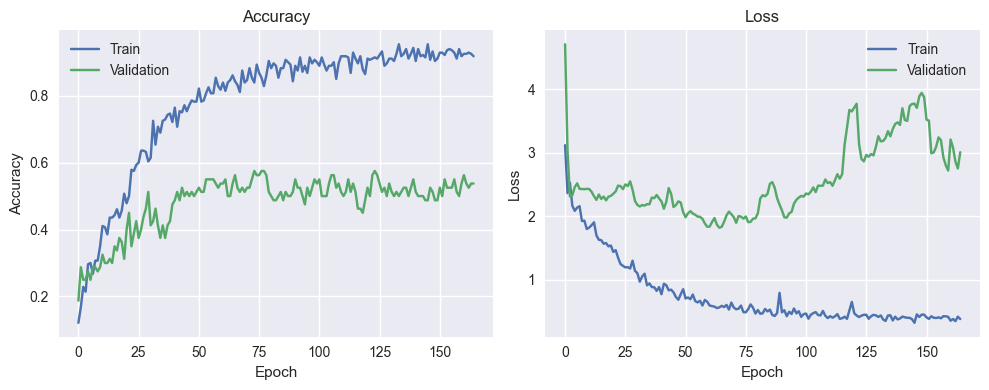

In [25]:
log_df = pd.read_csv('training_C2D.log')

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Evaluate the model and load the optimal weights:

In [27]:
[loss_test, acc_test] = modelC2D.evaluate(X_test_cnn, y_test, verbose=0)
print(f"Test loss: {loss_test}")
print(f"Test accuracy: {acc_test}")

modelC2D.load_weights('C2D_model.h5')
[loss_test, acc_test] = modelC2D.evaluate(X_test_cnn, y_test, verbose=0)
print(f"Test loss: {loss_test}")
print(f"Test accuracy: {acc_test}")


Test loss: 2.9663422107696533
Test accuracy: 0.5249999761581421
Test loss: 1.7568328380584717
Test accuracy: 0.5249999761581421


Display the confussion matrices for validation and test sets.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step 


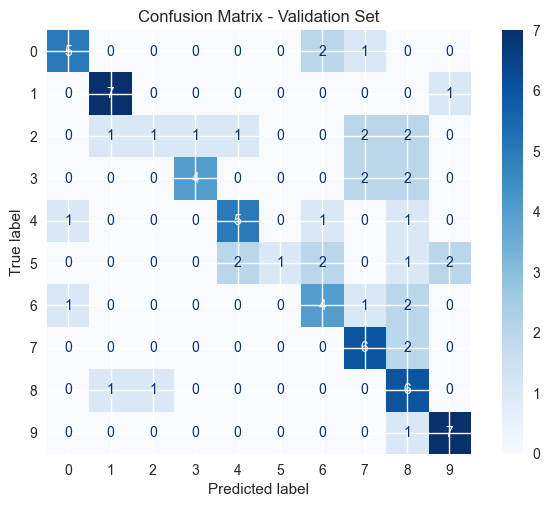

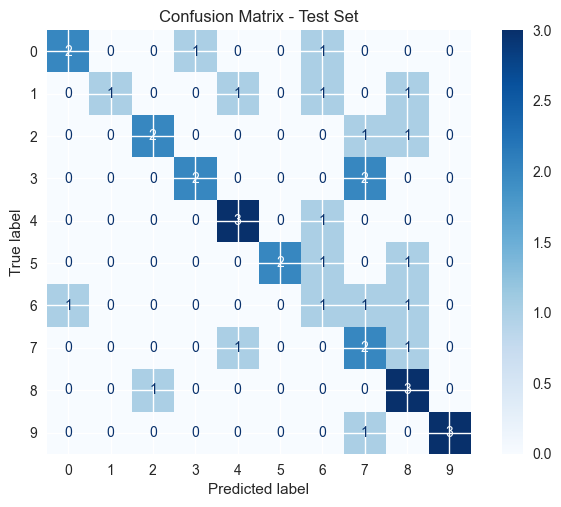

In [28]:
possible_classes = np.arange(0, 10)

pred_val = modelC2D.predict(X_val_cnn)
pred_test = modelC2D.predict(X_test_cnn)

pred_val_classes = np.argmax(pred_val, axis=1)
pred_test_classes = np.argmax(pred_test, axis=1)

cm = confusion_matrix(y_val, pred_val_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=possible_classes)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Validation Set')
plt.show()

cm = confusion_matrix(y_test, pred_test_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=possible_classes)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Test Set')
plt.show()

Print the classification_report for both validation and test sets.

In [31]:
print(classification_report(y_val, pred_val_classes))
print(classification_report(y_test, pred_test_classes))

              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.78      0.88      0.82         8
           2       0.50      0.12      0.20         8
           3       0.80      0.50      0.62         8
           4       0.62      0.62      0.62         8
           5       1.00      0.12      0.22         8
           6       0.44      0.50      0.47         8
           7       0.50      0.75      0.60         8
           8       0.35      0.75      0.48         8
           9       0.70      0.88      0.78         8

    accuracy                           0.57        80
   macro avg       0.64      0.57      0.55        80
weighted avg       0.64      0.57      0.55        80

              precision    recall  f1-score   support

           0       0.67      0.50      0.57         4
           1       1.00      0.25      0.40         4
           2       0.67      0.50      0.57         4
           3       0.67 

In [ ]:
train_size = 0.7
val_size = 0.2
test_size = 0.1

seed = 1234
X_temp, X_test, y_temp, y_test = train_test_split(Xdata, Ydata, test_size=test_size, random_state=seed, shuffle=True , stratify=Ydata)

from sklearn.model_selection import StratifiedKFold

kfolds = 5
skf = StratifiedKFold(n_splits=kfolds, shuffle=True, random_state=seed)

kfoldhistory = []

# Stratified K-Folds cross-validator
for fold, (train_index, val_index) in enumerate(skf.split(X_temp, y_temp)):
    X_train, X_val = X_temp[train_index], X_temp[val_index]
    y_train, y_val = y_temp[train_index], y_temp[val_index]
    print(f"Fold {fold + 1}/{kfolds}")

    # TRAINING
    history = modelC2D.fit(X_train_cnn, y_train, batch_size=batch_size, epochs=1000, validation_data=(X_val_cnn, y_val), callbacks=callbacks)
    kfoldhistory.append(history.history)
      
    # EVALUATION
    [loss_test, acc_test] = modelC2D.evaluate(X_test_cnn, y_test, verbose=0)

    .....

    
